# Vegetation indices and harvest detection

Loads the Sentinel-2 series, computes vegetation indices, detects candidate
harvest dates and plots the time series with the harvests marked.
Figures are saved to `figures/`, tables to `data/processed/`.

In [1]:
# ---- CONFIGURATION (edit here) ----
INDICES_TO_COMPUTE = ["NDVI", "EVI", "NDRE", "NDMI", "NDTI"]
INDICES_TO_PLOT = ["NDVI"]  # 1 or 2 indices
FIELDS_TO_PLOT = [1440, 1460]  # one figure per field
SHOW_HARVESTS = True  # mark candidate harvests with a red asterisk
SAVE_FIGURES = True

In [2]:
from pathlib import Path

import matplotlib.pyplot as plt

from cane_cycle.harvest import detect_harvests
from cane_cycle.io import load_s2_csv
from cane_cycle.plotting import plot_index_timeseries
from cane_cycle.vegetation_indices import add_indices, add_peak_band

# Works whether this runs from the project root or from notebooks/.
PROJECT_DIR = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
RAW_FILE = PROJECT_DIR / "data" / "raw" / "fields_example_s2.csv"
INDICES_FILE = PROJECT_DIR / "data" / "processed" / "s2_indices.csv"
HARVEST_FILE = PROJECT_DIR / "data" / "processed" / "harvest_dates.csv"
FIGURES_DIR = PROJECT_DIR / "figures"

In [3]:
df = load_s2_csv(RAW_FILE)
print(f"{len(df)} rows, fields: {sorted(df['field_id'].unique())}")
print(f"from {df['date'].min():%Y-%m-%d} to {df['date'].max():%Y-%m-%d}")
df.head()

947 rows, fields: [np.int64(1440), np.int64(1460)]
from 2019-01-10 to 2026-09-25


C:\Users\ju_fo\AppData\Local\Temp\ipykernel_4580\2064776681.py:1: UserWarning: Dropped 19 rows with unreadable band values on 12 dates: 2019-05-15, 2021-01-09, 2022-09-26, 2023-03-15, 2023-10-26, 2024-08-26, 2025-04-23, 2025-05-28, 2025-12-19, 2026-03-19, 2026-09-15, 2026-09-21
  df = load_s2_csv(RAW_FILE)


,fonte,date,field_id,granuleID,pixelTotal,B1,B2,B3,B4,B5,B6,B7,B8,B8A,B11,B12,coverage_pct
0,S2,2019-01-10,1440,L2A_T22K,4599,0.060076,0.080203,0.106059,0.147571,0.184043,0.212009,0.239522,0.249682,0.273818,0.417225,0.328715,100.0
1,S2,2019-01-15,1440,L2A_T22K,4599,0.569196,0.488870,0.464344,0.434051,0.493739,0.540574,0.558158,0.547149,0.566092,0.375156,0.358218,100.0
2,S2,2019-01-20,1440,L2A_T22K,4599,0.058165,0.080585,0.108030,0.156243,0.189861,0.207924,0.235563,0.242608,0.272648,0.438454,0.341696,100.0
3,S2,2019-01-25,1440,L2A_T22K,4599,0.064211,0.079458,0.108143,0.158343,0.191853,0.213444,0.234308,0.242552,0.273854,0.441287,0.334082,100.0
4,S2,2019-01-30,1440,L2A_T22K,4599,0.062121,0.084823,0.111290,0.161248,0.193650,0.210129,0.236431,0.244934,0.271180,0.439404,0.344913,100.0


In [4]:
df = add_indices(df, indices=INDICES_TO_COMPUTE)
df = add_peak_band(df)

INDICES_FILE.parent.mkdir(parents=True, exist_ok=True)
df.to_csv(INDICES_FILE, index=False)

df["peak_band"].value_counts()

peak_band
B8A    589
B11    287
B1      41
B8      23
B12      4
B5       1
B2       1
B7       1
Name: count, dtype: int64

In [5]:
harvests = detect_harvests(df)
harvests.to_csv(HARVEST_FILE, index=False)

print(harvests["kind"].value_counts().to_string())
harvests

kind
cane         10
rotation?     5


,field_id,harvest_date,last_green_date,first_low_date,uncertainty_days,peak_value,green_run_days,kind
0,1440,2019-04-20,2019-03-31,2019-04-10,10,0.300849,5,rotation?
1,1440,2020-05-29,2020-05-09,2020-05-19,10,0.426579,210,cane
2,1440,2021-09-06,2021-08-07,2021-08-12,5,0.491571,260,cane
3,1440,2023-09-26,2023-08-22,2023-09-01,10,0.319707,635,cane
4,1440,2024-01-24,2023-11-10,2023-11-15,5,0.325772,5,rotation?
5,1440,2024-10-30,2024-03-14,2024-03-19,5,0.293841,20,rotation?
6,1440,2025-11-04,2025-06-12,2025-06-17,5,0.472086,210,cane
7,1460,2019-10-02,2019-09-02,2019-09-07,5,0.396754,235,cane
8,1460,2020-10-11,2020-08-07,2020-08-12,5,0.449435,285,cane
9,1460,2021-09-11,2021-09-01,2021-09-06,5,0.352875,275,cane


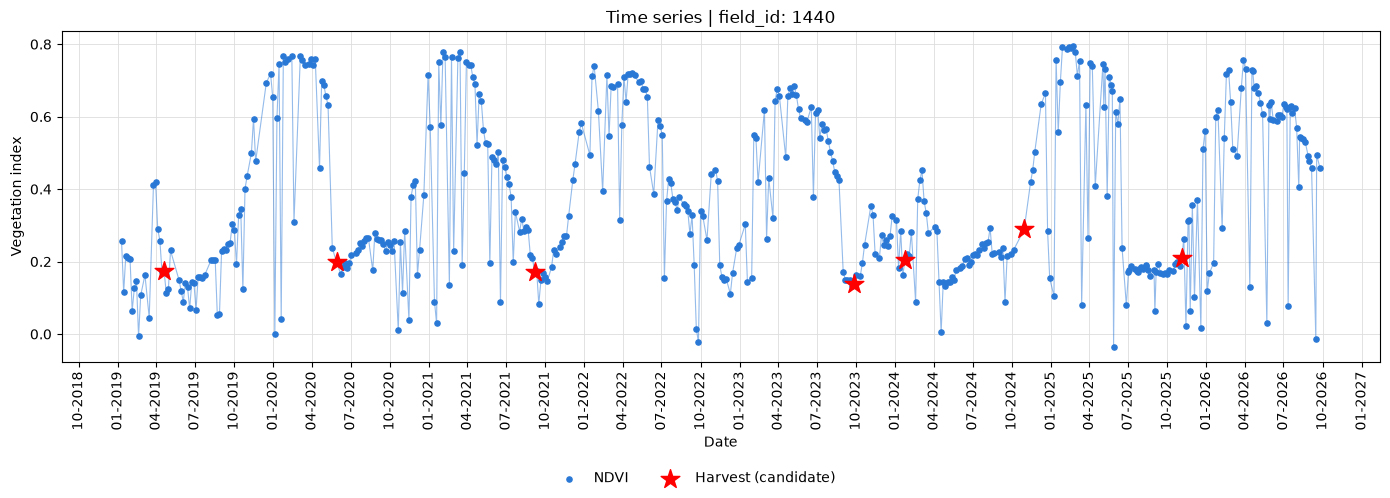

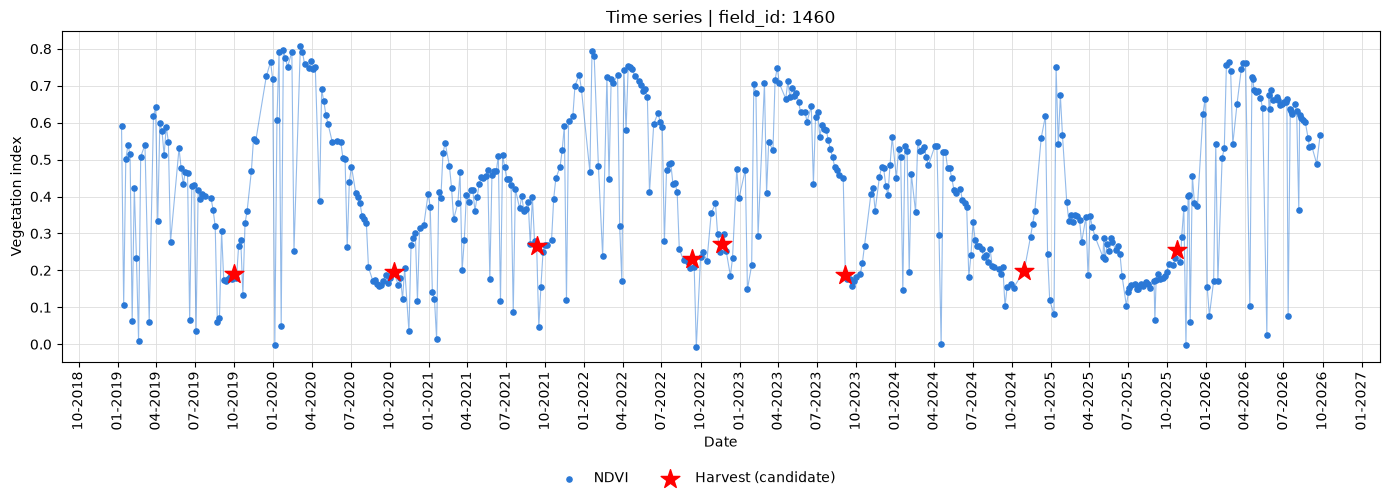

In [6]:
for field_id in FIELDS_TO_PLOT:
    save_path = None
    if SAVE_FIGURES:
        file_name = f"timeseries_{field_id}_{'_'.join(INDICES_TO_PLOT)}.png"
        save_path = FIGURES_DIR / file_name
    plot_index_timeseries(
        df,
        INDICES_TO_PLOT,
        field_id,
        harvests=harvests if SHOW_HARVESTS else None,
        save_path=save_path,
    )
    plt.show()